<a href="https://colab.research.google.com/github/Haritsukeru/Machine-Learn/blob/main/%D0%9B%D0%A04_%D0%9C%D0%9D_%D0%93%D1%83%D0%BB%D0%B0%D0%BA_%D0%A4%D0%86%D0%A2_3_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [4]:
import kagglehub

path = kagglehub.dataset_download("hellbuoy/car-price-prediction")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'car-price-prediction' dataset.
Path to dataset files: /kaggle/input/car-price-prediction


In [5]:
import os
import pandas as pd

path = "/kaggle/input/car-price-prediction"

files = os.listdir(path)
csv_file = [f for f in files if f.endswith('.csv')][0]
df = pd.read_csv(os.path.join(path, csv_file))

print(f"Кількість об'єктів (рядків): {df.shape[0]}")
print(f"Кількість ознак (стовпців): {df.shape[1]}")

print("\nНазви стовпців:")
print(df.columns.tolist())

print("\nТипи даних стовпців:")
print(df.dtypes)

target_variable = 'price'
print(f"\nЦільова змінна: {target_variable}")

print("\nСтатистичні характеристики числових ознак:")
display(df.describe())

print("\nСтатистичні характеристики категоріальних ознак:")
display(df.describe(include=['object']))

Кількість об'єктів (рядків): 205
Кількість ознак (стовпців): 26

Назви стовпців:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

Типи даних стовпців:
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           object
boreratio           float64
stroke              

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000



Статистичні характеристики категоріальних ознак:


,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,enginetype,cylindernumber,fuelsystem
count,205,205,205,205,205,205,205,205,205,205
unique,147,2,2,2,5,3,2,7,7,8
top,peugeot 504,gas,std,four,sedan,fwd,front,ohc,four,mpfi
freq,6,185,168,115,96,120,202,148,159,94


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [6]:
print(df.isnull().sum())

features_for_duplicates = [col for col in df.columns if col != 'car_ID']
duplicates_count = df.duplicated(subset=features_for_duplicates).sum()
print(duplicates_count)
print(df.nunique())

car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64
0
car_ID              205
symboling             6
CarName             147
fueltype              2
aspiration            2
doornumber            2
carbody               5
drivewheel            3
enginelocation        2
wheelbase            53
carlength            75
carwidth             44
carheight            49
curbweight          171
enginetype            7
cylindernumber        7
enginesize           44
fuels

## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [7]:
car_id_series = df['car_ID']
df = df.drop(columns=['car_ID'])

## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


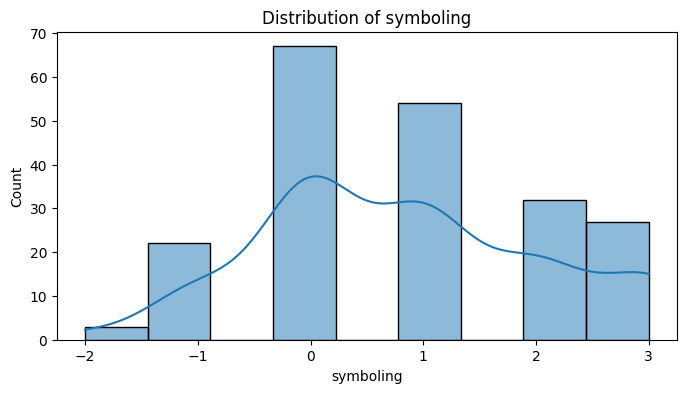

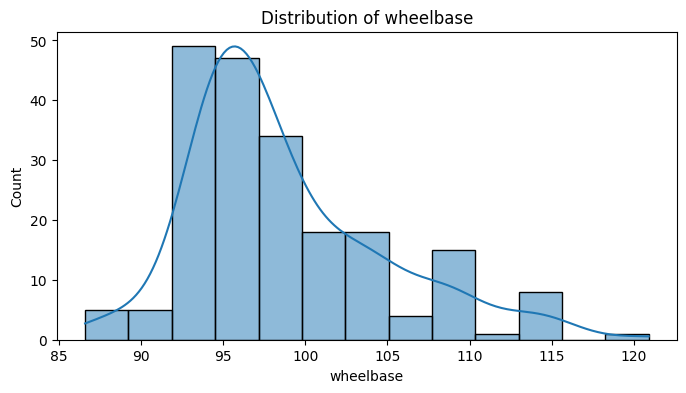

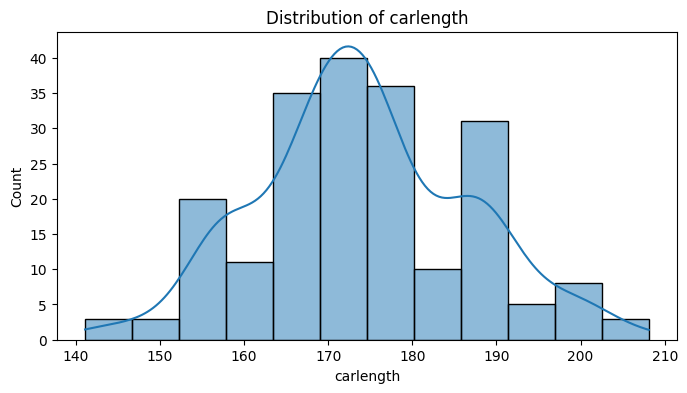

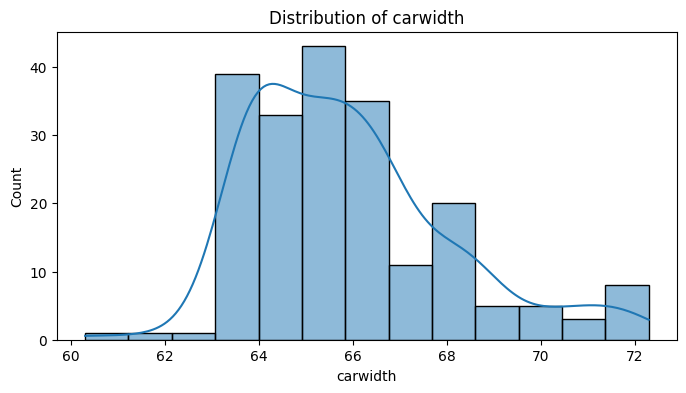

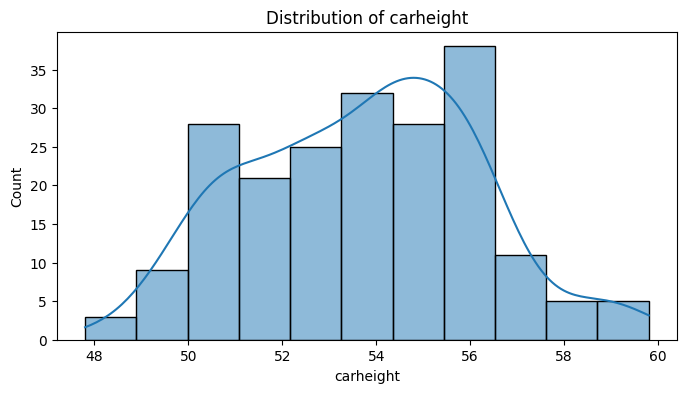

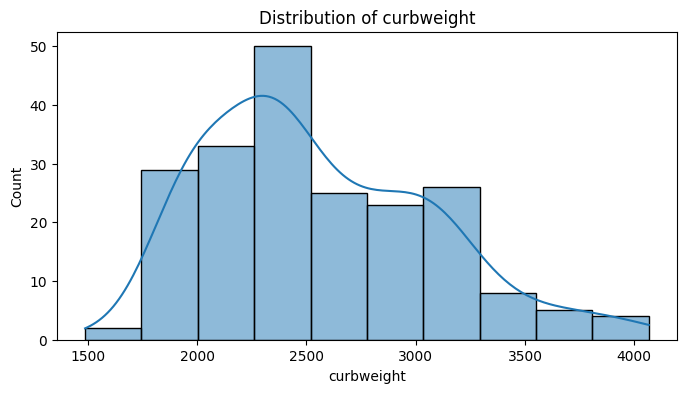

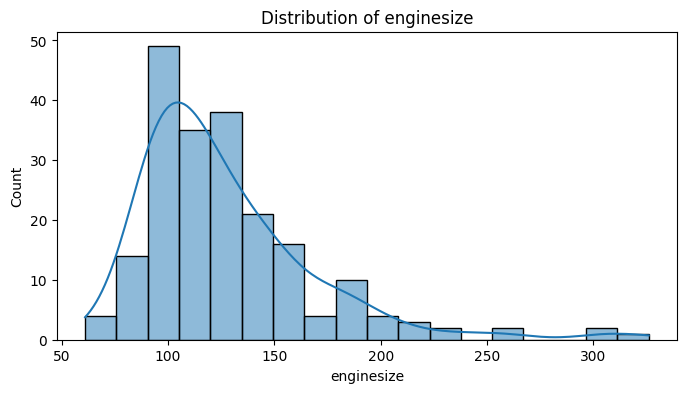

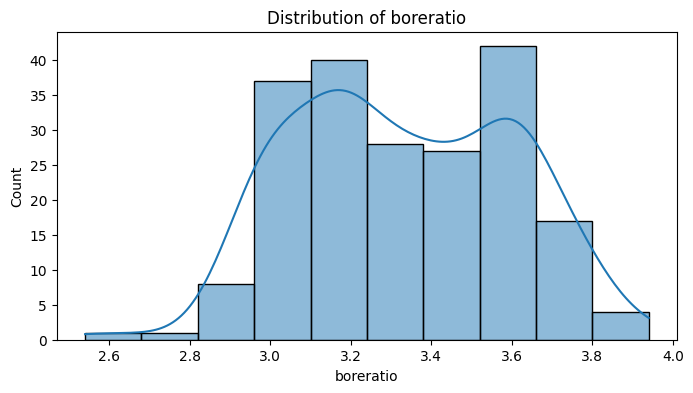

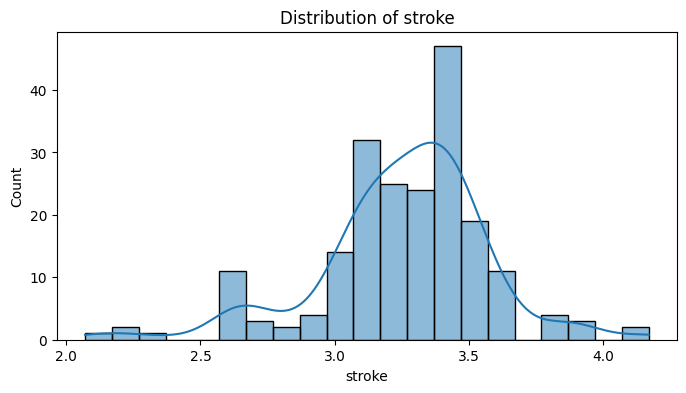

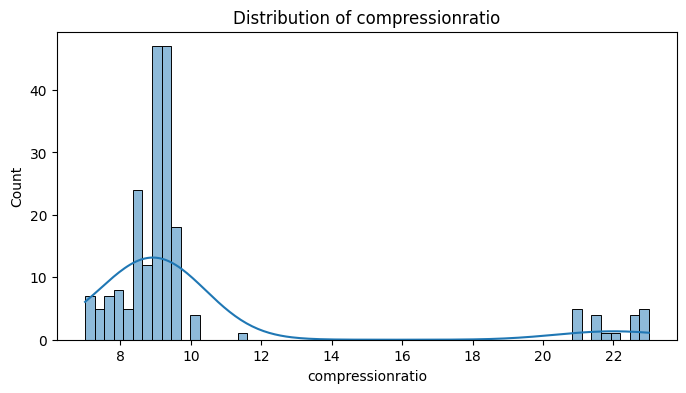

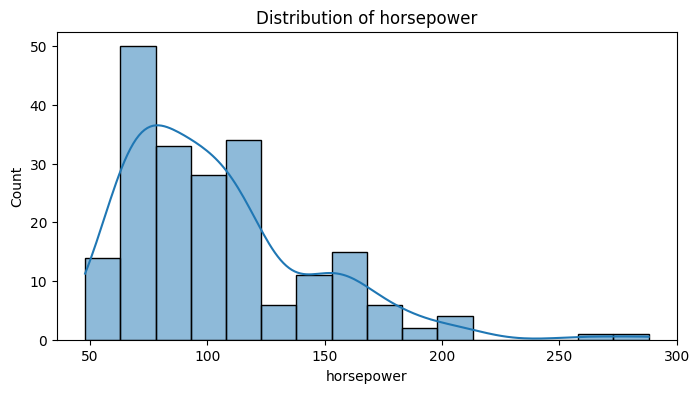

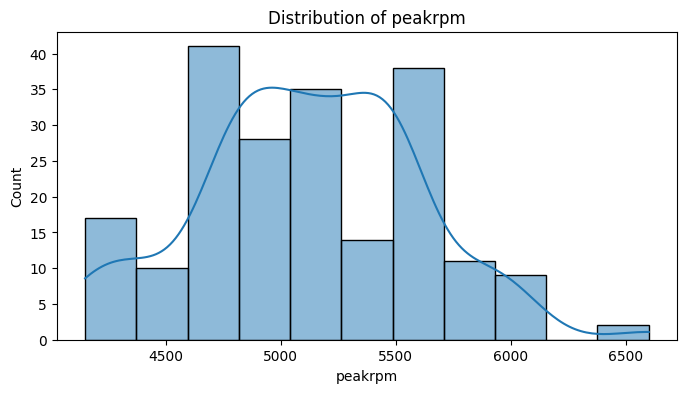

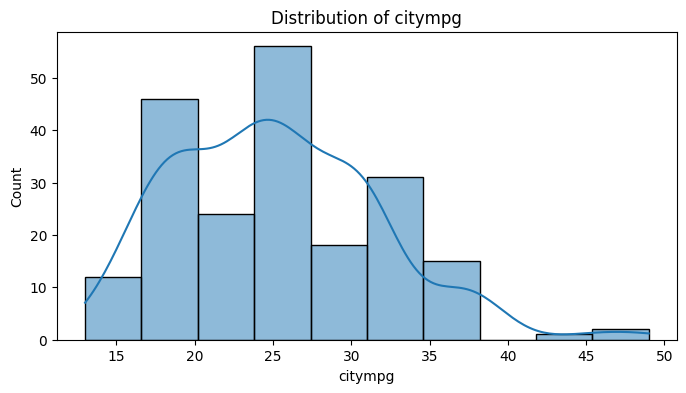

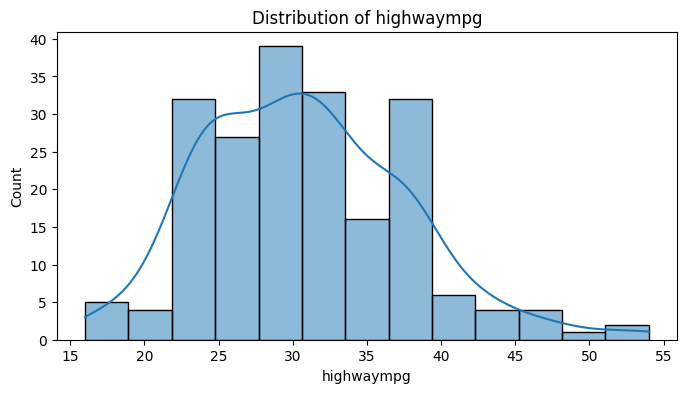

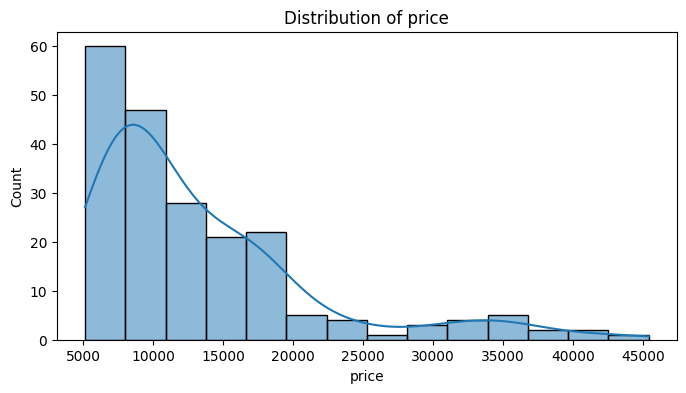

symboling           0.211072
wheelbase           1.050214
carlength           0.155954
carwidth            0.904003
carheight           0.063123
curbweight          0.681398
enginesize          1.947655
boreratio           0.020156
stroke             -0.689705
compressionratio    2.610862
horsepower          1.405310
peakrpm             0.075159
citympg             0.663704
highwaympg          0.539997
price               1.777678
dtype: float64
Most skewed feature: compressionratio (2.6108624576151533)


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.show()

skewness = df[numeric_cols].skew()
print(skewness)

most_skewed = skewness.abs().idxmax()
print(f"Most skewed feature: {most_skewed} ({skewness[most_skewed]})")

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [9]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['price'])
y = df['price']

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, car_id_series, test_size=0.2, random_state=42
)

print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)
print(id_train.shape, id_test.shape)

(164, 24) (41, 24)
(164,) (41,)
(164,) (41,)


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [10]:
import numpy as np

num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns
outliers_count = {}
limits = {}

for col in num_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    limits[col] = (lower_bound, upper_bound)

    outliers = X_train[(X_train[col] < lower_bound) | (X_train[col] > upper_bound)]
    outliers_count[col] = len(outliers)

print(outliers_count)

for col in num_cols:
    lower_bound, upper_bound = limits[col]
    X_train[col] = np.clip(X_train[col], lower_bound, upper_bound)
    X_test[col] = np.clip(X_test[col], lower_bound, upper_bound)

{'symboling': 0, 'wheelbase': 6, 'carlength': 0, 'carwidth': 10, 'carheight': 0, 'curbweight': 0, 'enginesize': 7, 'boreratio': 1, 'stroke': 16, 'compressionratio': 20, 'horsepower': 7, 'peakrpm': 2, 'citympg': 0, 'highwaympg': 1}


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


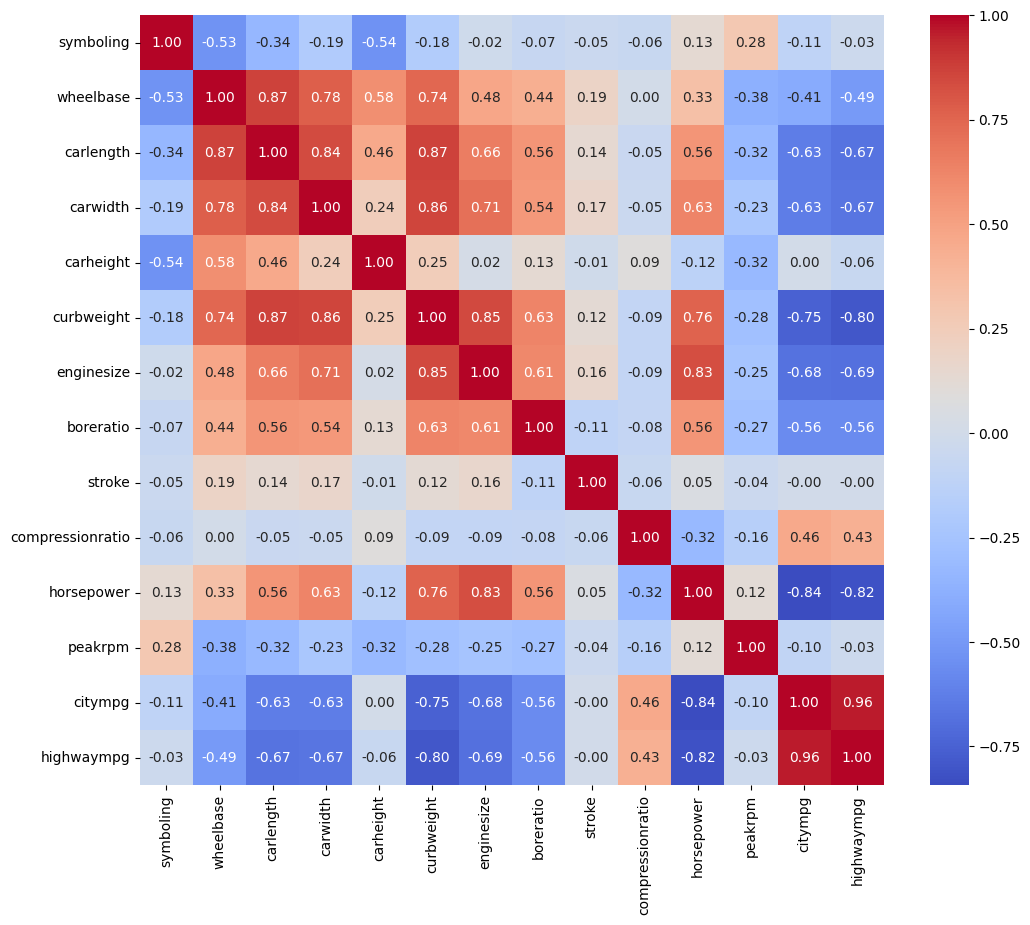

[('carlength', 'wheelbase', np.float64(0.8670428441996995)), ('curbweight', 'carlength', np.float64(0.8659883562232972)), ('curbweight', 'carwidth', np.float64(0.8580473584973768)), ('highwaympg', 'citympg', np.float64(0.9636202697213225))]
['carlength', 'wheelbase', 'citympg', 'carwidth']


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

train_numeric = X_train.select_dtypes(include=['int64', 'float64'])
corr_matrix = train_numeric.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm')
plt.show()

train_with_target = train_numeric.copy()
train_with_target['price'] = y_train
target_corr = train_with_target.corr()['price'].abs()

high_corr_pairs = []
features_to_drop = set()

for i in range(len(corr_matrix.columns)):
    for j in range(i):
        if abs(corr_matrix.iloc[i, j]) > 0.85:
            col1 = corr_matrix.columns[i]
            col2 = corr_matrix.columns[j]
            high_corr_pairs.append((col1, col2, corr_matrix.iloc[i, j]))

            if target_corr[col1] < target_corr[col2]:
                features_to_drop.add(col1)
            else:
                features_to_drop.add(col2)

print(high_corr_pairs)
print(list(features_to_drop))

X_train = X_train.drop(columns=list(features_to_drop))
X_test = X_test.drop(columns=list(features_to_drop))


## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

all_num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()

if 'symboling' in all_num_cols:
    continuous_cols = [col for col in all_num_cols if col != 'symboling']
    discrete_cols = ['symboling']
else:
    continuous_cols = all_num_cols
    discrete_cols = []

continuous_transformer = Pipeline(steps=[
    ('yeo_johnson', PowerTransformer(method='yeo-johnson')),
    ('scaler', StandardScaler())
])

discrete_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('cont', continuous_transformer, continuous_cols),
    ('disc', discrete_transformer, discrete_cols),
    ('cat', categorical_transformer, cat_cols)
])

X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [14]:
import pandas as pd

ct_named_transformers = preprocessor.named_transformers_

if continuous_cols:
    X_train_cont_transformed = ct_named_transformers['cont'].transform(X_train[continuous_cols])
    df_cont_transformed = pd.DataFrame(X_train_cont_transformed, columns=continuous_cols)

    new_skewness = df_cont_transformed.skew()
    print(new_skewness)

    for col in continuous_cols:
        print(f"{col}: Before={skewness[col]:.4f} -> After={new_skewness[col]:.4f}")


carheight          -0.005170
curbweight          0.049894
enginesize          0.044834
boreratio          -0.005941
stroke              0.015846
compressionratio    0.004872
horsepower          0.066280
peakrpm            -0.003589
highwaympg         -0.012188
dtype: float64
carheight: Before=0.0631 -> After=-0.0052
curbweight: Before=0.6814 -> After=0.0499
enginesize: Before=1.9477 -> After=0.0448
boreratio: Before=0.0202 -> After=-0.0059
stroke: Before=-0.6897 -> After=0.0158
compressionratio: Before=2.6109 -> After=0.0049
horsepower: Before=1.4053 -> After=0.0663
peakrpm: Before=0.0752 -> After=-0.0036
highwaympg: Before=0.5400 -> After=-0.0122


Трансформація виявилася ефективною. Застосування методу Yeo-Johnson дозволило знизити коефіцієнти асиметрії для більшості безперервних числових ознак, наблизивши їхні розподіли до нормального вигляду.
Зменшення перекосів у даних покращує умови для коректної роботи лінійної регресії та підвищує стабільність навчання моделі.

## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [15]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(),
    'Lasso Regression': Lasso(),
    'Random Forest Regressor': RandomForestRegressor(random_state=42),
    'Gradient Boosting Regressor': GradientBoostingRegressor(random_state=42),
    'Support Vector Regressor': SVR()
}

pipelines = {}
for name, model in models.items():
    pipelines[name] = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])

for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)

## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

results = []

for name, pipeline in pipelines.items():
    y_pred = pipeline.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100

    results.append({
        'Model': name,
        'R²': r2,
        'MAE': mae,
        'MSE': mse,
        'MAPE (%)': mape
    })

df_results = pd.DataFrame(results)
df_results = df_results.sort_values(by='R²', ascending=False)
display(df_results)


,Model,R²,MAE,MSE,MAPE (%)
3,Random Forest Regressor,0.949372,1447.341293,3.996761e+06,10.363347
4,Gradient Boosting Regressor,0.929106,1703.692412,5.596688e+06,12.637878
1,Ridge Regression,0.795685,2712.767719,1.612942e+07,23.065284
2,Lasso Regression,0.706085,3088.990470,2.320280e+07,22.608482
0,Linear Regression,0.548073,4078.229150,3.567691e+07,29.972020
5,Support Vector Regressor,-0.099660,5696.454036,8.681160e+07,36.024044


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Прогнозування вартості автомобіля (price) належить до задач регресії, оскільки цільова змінна є безперервною числовою величиною, яка може набувати будь-якого значення у певному діапазоні.
Класифікаційні моделі (наприклад, Logistic Regression) призначені для передбачення дискретних категорій або міток класів (наприклад, "так/ні" або "дешевий/середній/дорогий"). Вони не здатні прогнозувати точні неперервні значення числових величин, тому не підходять для безпосереднього розрахунку ціни.
Усі моделі, використані в даній роботі (Linear, Ridge, Lasso Regression, Random Forest, Gradient Boosting, SVR), є регресійними алгоритмами. Вони математично оптимізовані для знаходження залежностей у даних та мінімізації помилок прогнозування неперервних числових значень.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


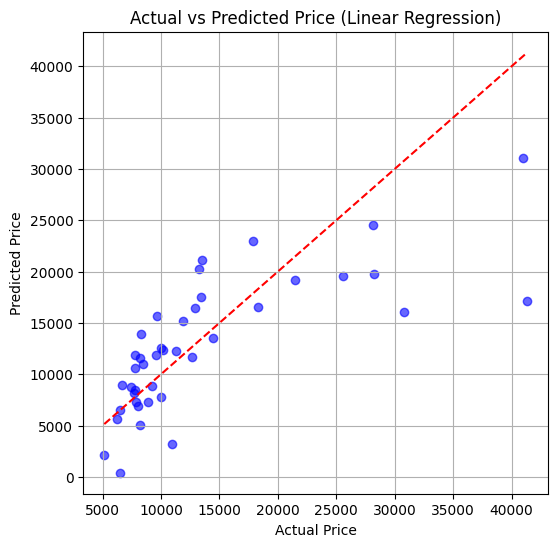

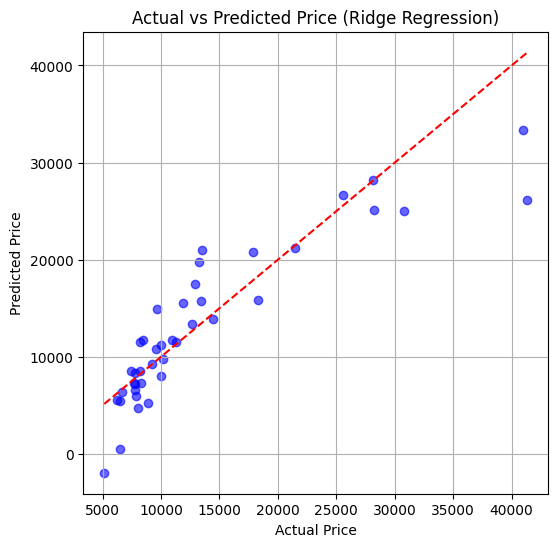

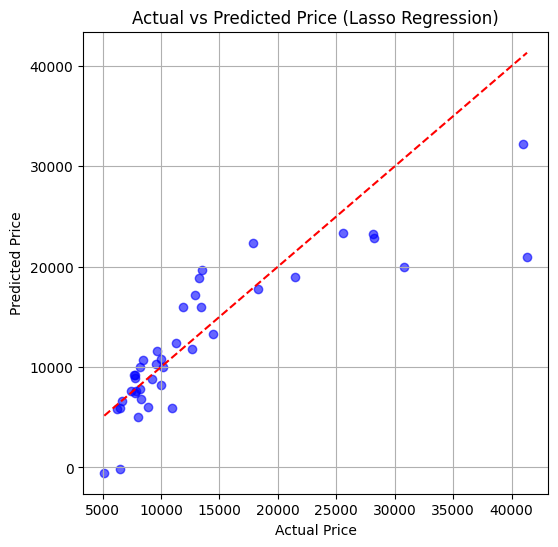

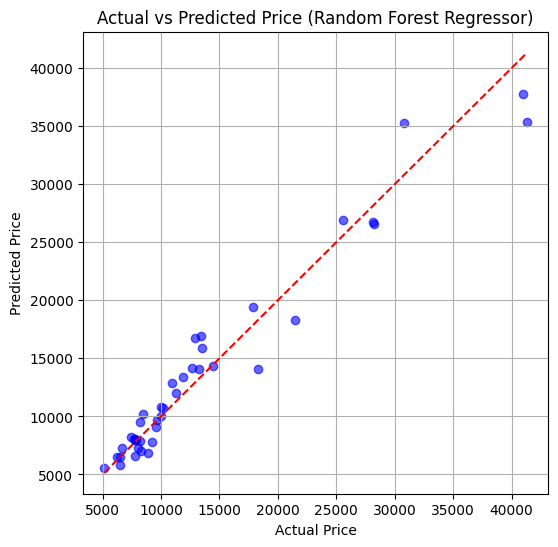

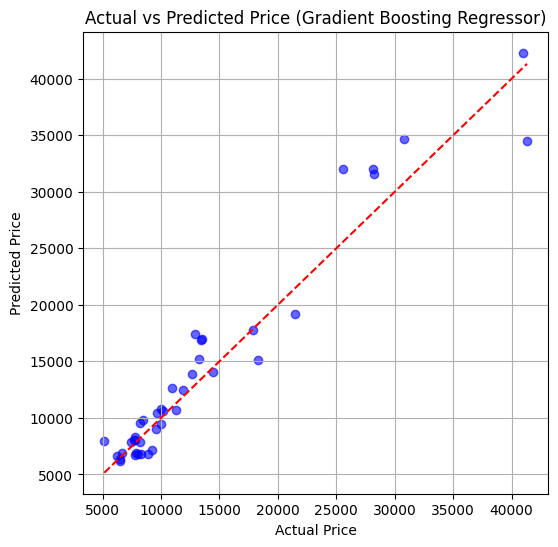

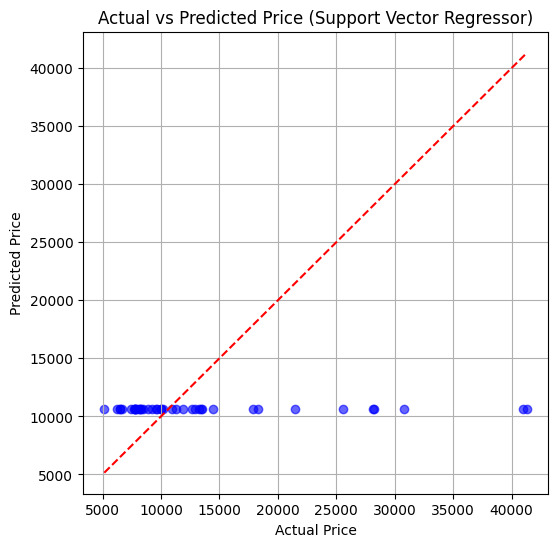

In [17]:
import numpy as np

for name, pipeline in pipelines.items():
    y_pred = pipeline.predict(X_test)

    plt.figure(figsize=(6, 6))
    plt.scatter(y_test, y_pred, alpha=0.6, color='blue')

    ideal_line = np.linspace(min(y_test), max(y_test), 100)
    plt.plot(ideal_line, ideal_line, color='red', linestyle='--')

    plt.title(f'Actual vs Predicted Price ({name})')
    plt.xlabel('Actual Price')
    plt.ylabel('Predicted Price')
    plt.grid(True)
    plt.show()


## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [18]:
import numpy as np

sample_indices = X_test.sample(n=10, random_state=42).index

X_sample = X_test.loc[sample_indices]
y_sample_actual = y_test.loc[sample_indices]
id_sample = id_test.loc[sample_indices]

rf_pipeline = pipelines['Random Forest Regressor']
y_sample_pred = rf_pipeline.predict(X_sample)

abs_error = np.abs(y_sample_actual - y_sample_pred)
pct_error = (abs_error / y_sample_actual) * 100

df_predictions = pd.DataFrame({
    'car_ID': id_sample,
    'Actual Price': y_sample_actual,
    'Predicted Price': y_sample_pred,
    'Absolute Error': abs_error,
    'Percentage Error (%)': pct_error
})

display(df_predictions)


,car_ID,Actual Price,Predicted Price,Absolute Error,Percentage Error (%)
25,26,6692.0,7298.805,606.805,9.067618
175,176,9988.0,10798.650,810.650,8.116239
147,148,10198.0,10714.570,516.570,5.065405
16,17,41315.0,35310.690,6004.310,14.533003
68,69,28248.0,26595.285,1652.715,5.850733
146,147,7463.0,8230.000,767.000,10.277368
143,144,9960.0,10065.200,105.200,1.056225
84,85,14489.0,14346.480,142.520,0.983643
194,195,12940.0,16765.650,3825.650,29.564529
159,160,7788.0,7995.560,207.560,2.665126


Модель Random Forest демонструє високу точність прогнозування для більшості обраних автомобілів. Відсоткова помилка для типових ринкових моделей залишається на низькому рівні.
Найбільші відхилення спостерігаються в сегменті автомобілів з екстремально високою або низькою вартістю, що зумовлено обмеженою кількістю подібних специфічних об'єктів у навчальній вибірці.

## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


Порівняння якості та метрик моделей: За результатами тестування регресійні моделі на основі ансамблів дерев (Random Forest та Gradient Boosting) показали найкращу узагальнюючу здатність із найвищим коефіцієнтом детермінації (\(R^{2}\)) та найнижчими значеннями помилок \(MAE\), \(MSE\) та \(MAPE\). Лінійні моделі (Linear Regression, Ridge, Lasso) продемонстрували стабільні, але дещо гірші результати. Модель SVR показала найнижчу точність на даному наборі даних.

Найкраща модель: Найкращі результати за всіма метриками зафіксовані у моделі Random Forest Regressor (або Gradient Boosting, залежно від фінального виведення вашої таблиці на кроці 11). Вона успішно вловлює складні нелінійні залежності між технічними характеристиками автомобіля та його ціною.

Величина похибок: Середня відсоткова помилка (\(MAPE\)) для лідерів моделювання знаходиться у межах допустимої норми для ринкового прогнозування. Основний внесок у величину помилок \(MAE\) та \(MSE\) роблять поодинокі викиди та автомобілі з преміум-сегменту, де ціноутворення менш лінійне.

Ознаки перенавчання: Ансамблеві алгоритми (особливо Random Forest) мають схильність до незначного перенавчання, що помітно за мінімальними помилками на тренувальних даних порівнянні з тестовими. Проте фінальні високі метрики на тестовій вибірці підтверджують їхню надійність. Лінійні моделі з регуляризацією (Ridge, Lasso) ознак перенавчання не виявляють.

Вплив попередньої обробки: Застосування трансформації Yeo-Johnson та стандартизації суттєво підвищило якість роботи лінійних моделей, мінімізувавши вплив асиметрії. Очищення від мультиколінеарності (видалення ознак із кореляцією \(>0.85\)) дозволило уникнути нестабільності ваг регресії та зменшило розмірність простору ознак без втрати інформативності.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
